<div style='background-color:#EEF4F7; border-left:4px solid #6F8996; border-radius:6px; padding:14px 18px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">Homework 10 - The Second Half of CRISP-DM</h1>
<p style="color:#243038; margin:0.4em 0;"><strong>LTAT.02.002 Introduction to Data Science - Autumn 2026</strong></p>
<p style="color:#243038; margin:0.4em 0;"><strong>Deadline: November 30th, 2026 at noon (12:00 Europe/Tallinn time)</strong></p>

</div>

Note! This homework is submitted as groups. One group member submits on behalf of the whole team.

Not every question fits every project. If a question does not apply to yours, first adapt it to your project, and then answer it.

Most questions have an empty code cell above the answer box. Use it if code, a table or a plot helps your answer, and leave it empty if it does not - for most questions a written answer on its own is enough. Where a question asks you to show the data or a graph, use the cell.

In the previous project homework (HW7) you worked out what your project is about and what is in your data. This one takes you through the rest of CRISP-DM: preparing the data, applying a method, judging the result, and getting it ready for other people to see.

**Your project does not have to be finished by the deadline of this homework.** It has to be finished by the poster deadline, one week later. The point of the questions below is to guide and help you finish your project on time.

Where this homework sits in the process:

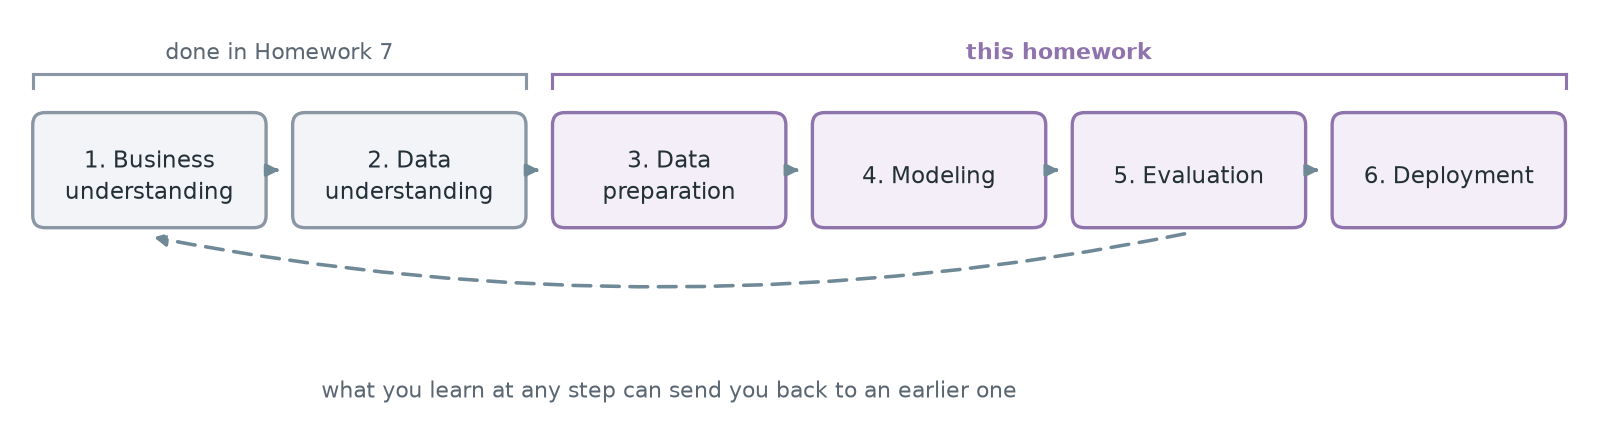

**Your project**

State these again, so that this notebook can be read on its own.

**Group ID and topic:** <span style="color:#B3261E;">Project F5: Road safety in Estonia</span>

**Team members:** <span style="color:#B3261E;">Milena Nikišina, Ratmir Bezrodnõi</span>

**Repository URL:** <span style="color:#B3261E;">https://github.com/m1nkq/RSIE</span>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">1. Data preparation (0.5 points)</h1>

</div>

This is **step 3** of CRISP-DM. The aim is to get from the raw data to a table you can actually work with, and to be able to say exactly what you changed and why. Someone reading your repository later should be able to repeat every one of those steps.

**a. Show the prepared data.**

Show the table your analysis runs on - the one you ended up with after cleaning, not the raw file you started from. Print its shape, the column names and the first few rows.

The rest of this task asks how you got from the raw data to this, so it helps to have it in front of you first.

In [1]:
import pandas as pd

# Load the original dataset
data = pd.read_csv(
    "lo_2011_2026.csv",
    sep=";",
    dtype={"Juhtumi nr": "string"}
)

# Convert the accident date and time to datetime
data["Toimumisaeg"] = pd.to_datetime(data["Toimumisaeg"])

# Keep only accidents from 2013 to 2025
data = data[data["Toimumisaeg"].dt.year.between(2013, 2025)]

# Remove duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

# Create additional variables for analysis
data["Year"] = data["Toimumisaeg"].dt.year
data["Fatal accident"] = data["Hukkunuid"] > 0

# Select the main columns for analysis
analysis_columns = [
    "Liiklusõnnetuse liik",
    "Juhtumi nr",
    "Toimumisaeg",
    "Hukkunuid",
    "Vigastatuid",
    "Maakond",
    "Ilmastik",
    "Valgustus",
    "Teekatte seisund",
    "Lubatud sõidukiirus",
    "Tee tüüp",
    "Year",
    "Fatal accident"
]

analysis_data = data[analysis_columns].copy()

# Display the prepared dataset
print("Dataset shape:", analysis_data.shape)

print("\nColumn names:")
print(analysis_data.columns.tolist())

print("\nFirst five rows:")
display(analysis_data.head())

Dataset shape: (19867, 13)

Column names:
['Liiklusõnnetuse liik', 'Juhtumi nr', 'Toimumisaeg', 'Hukkunuid', 'Vigastatuid', 'Maakond', 'Ilmastik', 'Valgustus', 'Teekatte seisund', 'Lubatud sõidukiirus', 'Tee tüüp', 'Year', 'Fatal accident']

First five rows:


,Liiklusõnnetuse liik,Juhtumi nr,Toimumisaeg,Hukkunuid,Vigastatuid,Maakond,Ilmastik,Valgustus,Teekatte seisund,Lubatud sõidukiirus,Tee tüüp,Year,Fatal accident
0,Ühesõidukiõnnetus,2101240172495,2024-09-19 22:14:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,NaN,KOV tee/tänav,2024,False
1,Ühesõidukiõnnetus,2101230084769,2023-07-22 05:06:00,0,1,Harju maakond,Selged olud,Valge aeg,Kuiv,20.0,Kergliiklustee,2023,False
2,Ühesõidukiõnnetus,3100220352836,2022-06-24 02:25:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,30.0,KOV tee/tänav,2022,False
3,Kokkupõrge,3100140090271,2014-11-16 00:15:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,50.0,KOV tee/tänav,2014,False
4,Kokkupõrge,3120140061769,2014-09-22 08:30:00,0,1,Viljandi maakond,Pilvised olud,Valge aeg,Kuiv,50.0,KOV tee/tänav,2014,False


<span style="color:#B3261E;"><strong>Answer:</strong></span> The prepared dataset contains 19,867 registered road traffic accidents in Estonia from 2013 to 2025 and 13 selected columns. The accident date and time were converted to datetime format, and duplicate rows were removed. Two additional columns, **Year** and **Fatal accident**, were created to support the analysis. The **Fatal accident** column indicates whether at least one person died in an accident. The analysis focuses on comparing the proportions of fatal accidents under different conditions rather than only absolute accident counts. The full cleaned dataset with 56 columns is retained for possible further analysis.

**b. What did you have to fix in the data?**

**Now go back to where you started.** List the problems you found - missing values, duplicates, impossible or inconsistent values, wrong data types - and say what you did with each one and why.

In [2]:
# Load the raw dataset for comparison
raw_data = pd.read_csv("lo_2011_2026.csv",
                       sep=";", dtype={"Juhtumi nr": "string"})

print("Original dataset shape:", raw_data.shape)
print("Prepared dataset shape:", data.shape)

# Check duplicate rows within the selected period
dates = pd.to_datetime(raw_data["Toimumisaeg"])
period_data = raw_data[dates.dt.year.between(2013, 2025)]

print("\nDuplicate rows:", period_data.duplicated().sum())

# Check missing values
missing = data.isna().sum()
print("\nMissing values:")
print(missing[missing > 0].sort_values(ascending=False))

# Check casualty counts
print("\nMissing casualty values:")
print(data[["Hukkunuid", "Vigastatuid"]].isna().sum())

print("\nNegative casualty values:")
print((data[["Hukkunuid", "Vigastatuid"]] < 0).sum())

# Check data types
print("\nData types:")
print(data[["Juhtumi nr", "Toimumisaeg",
            "Hukkunuid", "Fatal accident", "Year"]].dtypes)

# Check potentially unknown accident times
print("\nAccidents recorded at midnight:")
print((data["Toimumisaeg"].dt.strftime("%H:%M:%S") == "00:00:00").sum())

Original dataset shape: (23869, 54)
Prepared dataset shape: (19867, 56)

Duplicate rows: 1

Missing values:
Ristuv tänav                                     16912
Sõiduradade arv                                  14859
Tee km                                           10858
Tee nr                                           10849
Maja nr                                           9521
Tüüpskeemi nr                                     2256
Tüüpskeem                                         2256
Lubatud sõidukiirus                               2059
Tee element (detailne)                            1693
Tee element                                       1693
Tee objekt                                        1604
Kurvilisus                                        1432
Tee tasasus                                       1315
Tänav                                             1296
Tee seisund                                       1268
Ilmastik                                          1156
Teekate     

<span style="color:#B3261E;"><strong>Answer:</strong></span> The original dataset contained 23,869 rows and 54 columns. During data preparation, we identified and addressed the following issues:
- Time period: We restricted the dataset to 2013–2025 because geographical data for 2011–2012 were not corrected and the data for 2026 are incomplete.
- Duplicates: One duplicate row was identified within the selected period and removed to avoid counting the same record twice.
- Missing values: Several columns contained missing values, including weather conditions (1,156), lighting conditions (1,050), and county (2). We retained these records in the main dataset and will exclude missing values only from analyses involving the corresponding variables. This prevents unnecessary data loss.
- Incorrect data types: The accident date and time were converted to datetime format, and accident identifiers were stored as strings because they represent identifiers rather than numerical measurements.
- Impossible values: We checked the numbers of fatalities and injuries. No negative or missing values were found in these columns, so no corrections were necessary.
- Uncertain accident times: There were 105 accidents recorded at 00:00:00. Since this may represent an unknown accident time, we will exclude these records from time-of-day analysis but retain them for other comparisons.

After filtering and removing duplicates, the prepared dataset contains **19,867** rows and **56** columns, including two newly created variables: **Year** and **Fatal accident**.

**c. What does one row represent now, and what goes into the analysis?**

Name the columns you kept, any new columns you built from the existing ones, and the columns you left out.

In [3]:
# Select the main columns for analysis
analysis_columns = [
    "Liiklusõnnetuse liik",
    "Juhtumi nr",
    "Toimumisaeg",
    "Hukkunuid",
    "Vigastatuid",
    "Maakond",
    "Ilmastik",
    "Valgustus",
    "Teekatte seisund",
    "Lubatud sõidukiirus",
    "Tee tüüp",
    "Year",
    "Fatal accident"
]

# Create a separate dataset for analysis
analysis_data = data[analysis_columns].copy()

# Identify columns not selected for the main analysis
excluded_columns = [
    col for col in data.columns
    if col not in analysis_columns
]

print("Analysis dataset shape:", analysis_data.shape)

print("\nSelected columns:")
print(analysis_columns)

print("\nExcluded columns:")
print(excluded_columns)

display(analysis_data.head())

Analysis dataset shape: (19867, 13)

Selected columns:
['Liiklusõnnetuse liik', 'Juhtumi nr', 'Toimumisaeg', 'Hukkunuid', 'Vigastatuid', 'Maakond', 'Ilmastik', 'Valgustus', 'Teekatte seisund', 'Lubatud sõidukiirus', 'Tee tüüp', 'Year', 'Fatal accident']

Excluded columns:
['Isikuid', 'Sõidukeid', 'Aadress', 'Tänav', 'Maja nr', 'Ristuv tänav', 'Tee nr', 'Tee km', 'Omavalitsus', 'Asustusüksus', 'Asula', 'Liiklusõnnetuse liik (detailne)', 'Kergliikurijuhi osalusel', 'Jalakäija osalusel', 'Kaassõitja osalusel', 'Maastikusõiduki juhi osalusel', 'Eaka (65+) mootorsõidukijuhi osalusel', 'Bussijuhi osalusel', 'Veoautojuhi osalusel', 'Ühissõidukijuhi osalusel', 'Sõiduautojuhi osalusel', 'Mootorratturi osalusel', 'Mopeedijuhi osalusel', 'Jalgratturi osalusel', 'Alaealise osalusel', 'Esmase juhiloa omaniku osalusel', 'Turvavarustust mitte kasutanud isiku osalusel', 'Mootorsõidukijuhi osalusel', 'Tüüpskeemi nr', 'Tüüpskeem', 'Tee tüüp (detailne)', 'Tee liik', 'Tee element', 'Tee element (detailne)

,Liiklusõnnetuse liik,Juhtumi nr,Toimumisaeg,Hukkunuid,Vigastatuid,Maakond,Ilmastik,Valgustus,Teekatte seisund,Lubatud sõidukiirus,Tee tüüp,Year,Fatal accident
0,Ühesõidukiõnnetus,2101240172495,2024-09-19 22:14:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,NaN,KOV tee/tänav,2024,False
1,Ühesõidukiõnnetus,2101230084769,2023-07-22 05:06:00,0,1,Harju maakond,Selged olud,Valge aeg,Kuiv,20.0,Kergliiklustee,2023,False
2,Ühesõidukiõnnetus,3100220352836,2022-06-24 02:25:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,30.0,KOV tee/tänav,2022,False
3,Kokkupõrge,3100140090271,2014-11-16 00:15:00,0,1,Harju maakond,Selged olud,Pimeda aeg,Kuiv,50.0,KOV tee/tänav,2014,False
4,Kokkupõrge,3120140061769,2014-09-22 08:30:00,0,1,Viljandi maakond,Pilvised olud,Valge aeg,Kuiv,50.0,KOV tee/tänav,2014,False


<span style="color:#B3261E;"><strong>Answer:</strong></span> Each row represents one registered road traffic accident involving injuries or fatalities in Estonia between 2013 and 2025.

The following columns were selected for the main analysis:
- Accident identification: **Juhtumi nr**, **Toimumisaeg**.
- Accident severity: **Hukkunuid**, **Vigastatuid**.
- Geographical information: **Maakond**.
- Environmental conditions: **Ilmastik**, **Valgustus**, **Teekatte seisund**.
- Road characteristics: **Lubatud sõidukiirus**, **Tee tüüp**.
- Accident type: **Liiklusõnnetuse liik**.

Two new columns were created:
- **Year**: Extracted from the accident date to analyse changes over time.
- **Fatal accident**: A Boolean variable indicating whether at least one person died in the accident.

The remaining 43 columns were excluded from the main analysis because they contain more detailed information about locations, road infrastructure, vehicle types, and accident participants that is not directly required for our main research questions. However, these columns were retained in the full dataset for possible further analysis.

The resulting analysis dataset contains **19,867** rows and **13** columns.

**d. How did you split the data, and why that way?**

Randomly, by time, or by group? Then name one thing in your data that could **leak** the answer into the inputs, and say how you avoided it. A leak is information that would not be available at the moment the prediction is made - for example a column that is only filled in after the outcome is already known.

If your project does not predict anything, answer instead how you made sure your conclusions are not driven by one unusual part of the data.

In [4]:
# Compare accident proportions across years
yearly_summary = analysis_data.groupby("Year").agg(
    total_accidents=("Fatal accident", "size"),
    fatal_accidents=("Fatal accident", "sum"),
    fatal_percentage=("Fatal accident", "mean")
)

yearly_summary["fatal_percentage"] *= 100

print("Accidents by year:")
display(yearly_summary.round(2))

# Compare accident proportions across counties
county_summary = analysis_data.groupby("Maakond").agg(
    total_accidents=("Fatal accident", "size"),
    fatal_accidents=("Fatal accident", "sum"),
    fatal_percentage=("Fatal accident", "mean")
)

county_summary["fatal_percentage"] *= 100

print("Accidents by county:")
display(county_summary.round(2))

# Select accidents with known lighting conditions
lighting_data = analysis_data[
    analysis_data["Valgustus"].isin(
        ["Pimeda aeg", "Valge aeg"]
    )
]

# Compare lighting conditions across years
lighting_summary = lighting_data.pivot_table(
    index="Year",
    columns="Valgustus",
    values="Fatal accident",
    aggfunc="mean"
) * 100

print("Fatal accident percentages by year and lighting:")
display(lighting_summary.round(2))

Accidents by year:


,total_accidents,fatal_accidents,fatal_percentage
Year,,,
2013,1362,76,5.58
2014,1404,74,5.27
2015,1374,60,4.37
2016,1464,63,4.30
2017,1414,44,3.11
2018,1473,64,4.34
2019,1439,51,3.54
2020,1406,55,3.91
2021,1573,52,3.31


Accidents by county:


,total_accidents,fatal_accidents,fatal_percentage
Maakond,,,
Harju maakond,10234,202,1.97
Hiiu maakond,78,6,7.69
Ida-Viru maakond,1616,69,4.27
Järva maakond,446,35,7.85
Jõgeva maakond,389,25,6.43
Lääne maakond,285,19,6.67
Lääne-Viru maakond,825,59,7.15
Pärnu maakond,1336,67,5.01
Põlva maakond,347,10,2.88


Fatal accident percentages by year and lighting:


Valgustus,Pimeda aeg,Valge aeg
Year,,
2013,8.72,4.35
2014,9.41,3.69
2015,7.01,3.37
2016,7.44,3.03
2017,4.69,2.54
2018,4.55,4.22
2019,4.12,3.52
2020,5.48,3.66
2021,4.70,3.06


<span style="color:#B3261E;"><strong>Answer:</strong></span> Our project uses descriptive analysis rather than predictive modelling. Therefore, we did not split the dataset into training and testing sets. Instead, we grouped the data by year, county, and lighting conditions to check whether the observed patterns were consistent across different subsets of the data.

The yearly analysis showed an overall decrease in the proportion of fatal accidents, from 5.58% in 2013 to 2.29% in 2025. We also compared counties and considered differences in sample sizes, as percentages based on smaller groups may be less reliable.

Furthermore, the proportion of fatal accidents during dark conditions was higher than during daylight in all 13 years. This suggests that the observed pattern is not driven by one unusual year. Records with unknown lighting conditions were excluded from this comparison.

Since the dataset contains only registered accidents involving injuries or fatalities and does not include traffic volume, our conclusions describe differences within the recorded accidents rather than the actual risk of experiencing an accident.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 1 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">2. Modeling (0.5 points)</h1>

</div>

This is **step 4**. The point is not to reach the best possible result - it is to have something that works from end to end, and something simple to compare it against.

**a. Start with a baseline.**

Your baseline is the simplest thing that is not your method. For a prediction task that is the majority class, the mean, or an obvious rule. For a clustering or descriptive task it is the picture you would get without the method - everything in one group, or the overall average with no breakdown. Report what it gives you.

In [5]:
# Calculate the overall percentage of fatal accidents
total_accidents = len(analysis_data)
fatal_accidents = analysis_data["Fatal accident"].sum()
baseline = fatal_accidents / total_accidents * 100

print("Total accidents:", total_accidents)
print("Fatal accidents:", fatal_accidents)
print("Baseline:", round(baseline, 2), "%")

Total accidents: 19867
Fatal accidents: 739
Baseline: 3.72 %


<span style="color:#B3261E;"><strong>Answer:</strong></span> Our baseline is the overall percentage of fatal accidents in Estonia from 2013 to 2025, without separating them by weather, lighting or other conditions.

Out of 19,867 recorded accidents involving injuries or fatalities, 739 were fatal, giving a baseline of 3.72%. We will use this as a reference when comparing accident severity across different groups.

**b. Now your actual method.**

Which method did you use, and why is it a reasonable choice for your kind of problem - classification, regression, clustering, or description?

In [6]:
# Compare fatal accident percentages by lighting
lighting_comparison = lighting_data.groupby("Valgustus").agg(
    total_accidents=("Fatal accident", "size"),
    fatal_accidents=("Fatal accident", "sum"),
    fatal_percentage=("Fatal accident", "mean")
)

lighting_comparison["fatal_percentage"] *= 100

display(lighting_comparison.round(2))

,total_accidents,fatal_accidents,fatal_percentage
Valgustus,,,
Pimeda aeg,5042,290,5.75
Valge aeg,13575,443,3.26


<span style="color:#B3261E;"><strong>Answer:</strong></span> We use descriptive analysis to compare the proportions of fatal accidents under different conditions. We group accidents by factors such as lighting, year and county, and calculate the total number of accidents, the number of fatal accidents and their percentage in each group.

This method is suitable for our project because we want to understand patterns in historical data rather than predict future accidents. Comparing percentages also helps us see differences that might not be clear from accident counts alone.

**c. How do you measure success?**

Name the measure you report and say why it fits your goal. (For example accuracy, precision, recall, F1 or ROC AUC for classification, RMSE or MAE for regression - or something else that suits your project.)

In [7]:
# Compare each group with the baseline
lighting_comparison["difference_from_baseline"] = (
    lighting_comparison["fatal_percentage"] - baseline
)

display(lighting_comparison.round(2))

,total_accidents,fatal_accidents,fatal_percentage,difference_from_baseline
Valgustus,,,,
Pimeda aeg,5042,290,5.75,2.03
Valge aeg,13575,443,3.26,-0.46


<span style="color:#B3261E;"><strong>Answer:</strong></span> Our main measure is the percentage of fatal accidents in each group. We compare it with the overall baseline of 3.72% to see how accident severity differs depending on the conditions.

We also report the total number of accidents in each group, because percentages based on very few accidents may be less reliable.

These measures fit our goal because we want to compare proportions and identify meaningful patterns rather than predict individual accidents.

**d. What did you try, and how did you choose?**

Different settings, different parameters, several methods - say what you compared and on what basis you picked one.

In [8]:
# Compare different ways of grouping accidents

print("By year:")
display(yearly_summary.round(2))

print("By county:")
display(county_summary.round(2))

print("By lighting:")
display(lighting_comparison.round(2))

By year:


,total_accidents,fatal_accidents,fatal_percentage
Year,,,
2013,1362,76,5.58
2014,1404,74,5.27
2015,1374,60,4.37
2016,1464,63,4.30
2017,1414,44,3.11
2018,1473,64,4.34
2019,1439,51,3.54
2020,1406,55,3.91
2021,1573,52,3.31


By county:


,total_accidents,fatal_accidents,fatal_percentage
Maakond,,,
Harju maakond,10234,202,1.97
Hiiu maakond,78,6,7.69
Ida-Viru maakond,1616,69,4.27
Järva maakond,446,35,7.85
Jõgeva maakond,389,25,6.43
Lääne maakond,285,19,6.67
Lääne-Viru maakond,825,59,7.15
Pärnu maakond,1336,67,5.01
Põlva maakond,347,10,2.88


By lighting:


,total_accidents,fatal_accidents,fatal_percentage,difference_from_baseline
Valgustus,,,,
Pimeda aeg,5042,290,5.75,2.03
Valge aeg,13575,443,3.26,-0.46


<span style="color:#B3261E;"><strong>Answer:</strong></span> We compared three ways of grouping accidents: by year, county and lighting conditions. For each group, we examined the number of accidents and the percentage of fatal accidents.

Grouping by year helps us understand how accident severity changes over time, while grouping by county shows geographical differences. We chose lighting conditions as our main comparison because the two groups are easy to compare, and we can also check whether the differences remain consistent across different years.

We will still use the other groupings to provide additional context for our results.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 2 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">3. Evaluation (0.5 points)</h1>

</div>

This is **step 5**. Steps 4 and 5 are easy to confuse. Step 4 asks whether the method ran; step 5 asks whether the result is any good, and whether it answers the question you started from.

**a. Put the numbers side by side.**

Your baseline and your method, measured on data the method did not learn from. A small table or a plot is enough.

In [9]:
# Compare the baseline with lighting conditions
comparison = lighting_comparison[[
    "total_accidents", "fatal_accidents", "fatal_percentage"
]].copy()

comparison.loc["Overall baseline"] = [
    total_accidents,
    fatal_accidents,
    baseline
]

display(comparison.round(2))

,total_accidents,fatal_accidents,fatal_percentage
Valgustus,,,
Pimeda aeg,5042.0,290.0,5.75
Valge aeg,13575.0,443.0,3.26
Overall baseline,19867.0,739.0,3.72


<span style="color:#B3261E;"><strong>Answer:</strong></span> We compared the overall baseline of 3.72% with the percentages of fatal accidents during daylight and darkness. This allows us to see how the proportions differ between lighting conditions instead of looking only at the total number of accidents.

Since our project is descriptive, we did not train a predictive model or use a train/test split. However, we also compared the proportions across individual years to check whether the differences were consistent. The percentages of fatal accidents in darkness was higher than in daylight in all 13 years.

These results suggest that lighting conditions are associated with differences in accident severity, although they do not prove that darkness itself causes more severe accidents.

**b. What does your result actually mean for someone who would use it?**

A number on its own - "accuracy 0.87" - does not tell anyone whether the work was worth doing. Say what someone could now do that they could not do before, and whether your result is good enough for them to rely on.

<span style="color:#B3261E;"><strong>Answer:</strong></span> Our results show that the proportion of fatal accidents is higher in darkess (5.75%) than in daylight (3.26%). This difference was also observed across all 13 years in our dataset.

For Transpordiamet, this could help identify lighting conditions as an important factor to investigate futher when studying road safety. The results could be useful for deciding which questions deserve more attention.

However, our findings are not enough to make specific road safety decisions on their own. Other factors, such as traffic volume, speed and road type, may also affect accident severity. More detailed analysis would be needed before recommending specific safety measures.

**c. What is the biggest threat to your conclusion?**

Too little data, a leak, a sample that does not represent what you claim, a measure that flatters your method - name the one that worries you most, and say how much it worries you.

<span style="color:#B3261E;"><strong>Answer:</strong></span> The biggest limitation of our analysis is that other factors may influence the differences we observe between groups. For example, the higher proportion of fatal accidents in darkness might also be related to speed limits, road types or other conditions, not just lighting.

This is important because we cannot say that darkness itself causes more severe accidents. However, we can still identify and compare patterns in the data, which is the main goal of our project.

To better understand these differences, we could compare accidents within similar road types or speed limit categories in our further analysis.

**d. Did anything send you back to an earlier step?**

Look at the diagram at the top of this notebook. If something you found here made you change the data preparation, the method, or even the question itself, say which step you went back to and what you changed. If nothing did, say that.

<span style="color:#B3261E;"><strong>Answer:</strong></span> After reviewing our results, we realized that simply grouping accidents and comparing percentages might not be enough for a deeper analysis. Although we found differences in fatal accident proportions, we still need to understand how reliable these differences are and whether other factors could influence them.

Because of this, we decided to revisit the Modeling step and expand our analysis by adding confidence intervals and statistical tests. We also plan to compare daylight and darkness within similar road types or speed limit categories to see whether the differences remain consistent.

We are keeping our original research goals, but improving our approach to make the conclusions more reliable and meaningful.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 3 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#F3EEF8; border-top:1px solid #D8CCE5; border-left:4px solid #8F73AC; border-radius:6px; padding:10px 16px; margin-top:24px; color:#243038;'>

<h1 style="color:#243038; margin:0.2em 0;">4. Towards the poster (0.5 points)</h1>

</div>

This is **step 6**, deployment. In a company this is where the result is put to use; on this course your poster and your repository are how your work reaches other people.

**These do not have to be the figures that end up on your poster.** You still have a week to make those. The point here is to work out *now* what in your project can actually be shown as a graph, and to have a first version in front of you that you can improve if needed.

**a. Two or three graphs from your project.**

Label the axes on each one. Then, in the answer below, write one sentence per graph saying what a reader should take from it.

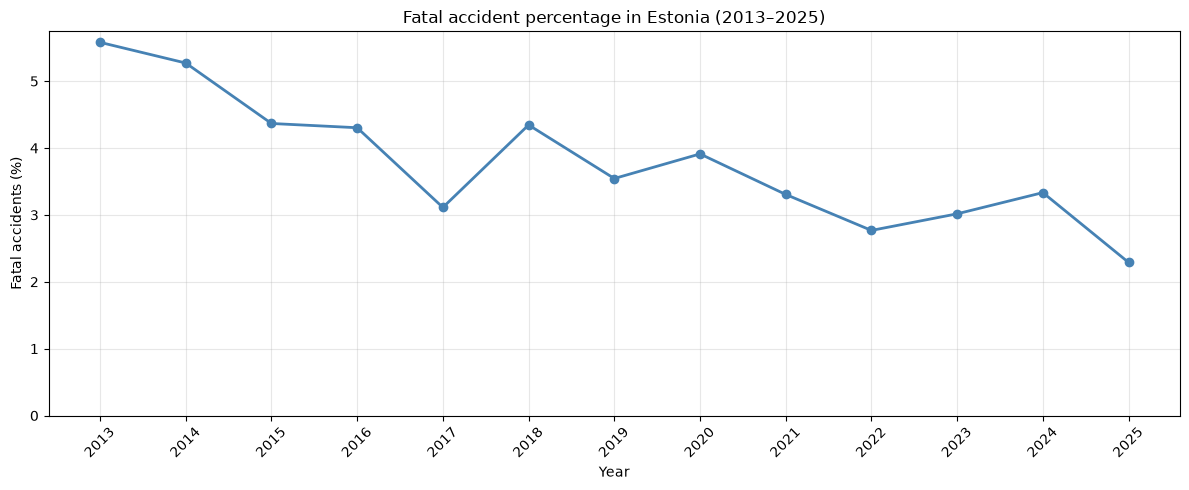

In [10]:
import matplotlib.pyplot as plt

# Plot the yearly percentage of fatal accidents
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_summary.index,
    yearly_summary["fatal_percentage"],
    marker="o",
    color="steelblue",
    linewidth=2
)

plt.title("Fatal accident percentage in Estonia (2013–2025)")
plt.xlabel("Year")
plt.ylabel("Fatal accidents (%)")

plt.xticks(yearly_summary.index, rotation=45)
plt.ylim(bottom=0)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

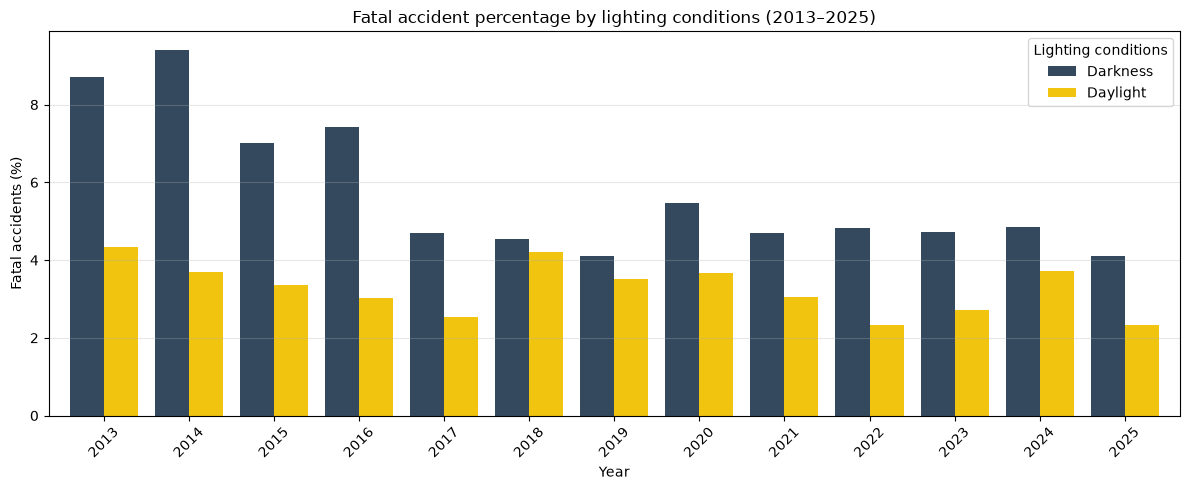

In [11]:
# Rename lighting categories for the graph
lighting_plot = lighting_summary.rename(columns={
    "Pimeda aeg": "Darkness",
    "Valge aeg": "Daylight"
})

# Compare fatal accident percentages by lighting conditions
lighting_plot.plot(
    kind="bar",
    figsize=(12, 5),
    color=["#34495e", "#f1c40f"],
    width=0.8
)

plt.title("Fatal accident percentage by lighting conditions (2013–2025)")
plt.xlabel("Year")
plt.ylabel("Fatal accidents (%)")

plt.xticks(rotation=45)
plt.legend(title="Lighting conditions")
plt.grid(axis="y", alpha=0.3)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

,total_accidents,fatal_accidents,fatal_percentage
Ilmastik,,,
"Lörts, rahe",3,1,33.33
Tuisune või tormine,42,8,19.05
Lumised olud,549,41,7.47
Udused olud,102,7,6.86
Vihmasadu,885,51,5.76
Pilvised olud,7014,263,3.75
Selged olud,9604,353,3.68
Madal vastu paistev päike,267,7,2.62
Pole teada,230,2,0.87


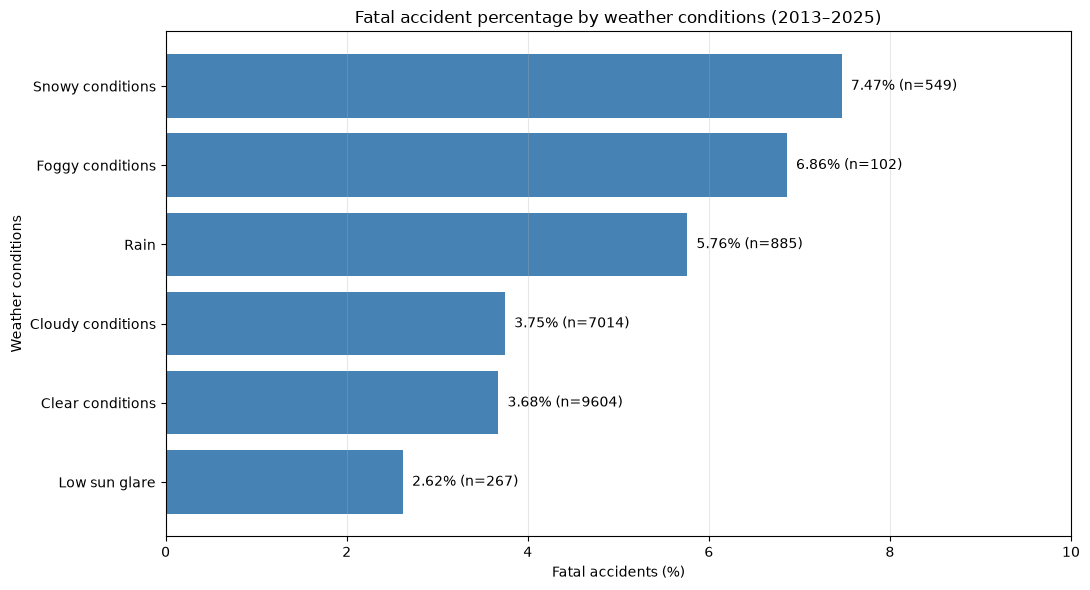

In [12]:
# Summarise accidents by weather conditions
weather_summary = analysis_data.groupby("Ilmastik").agg(
    total_accidents=("Fatal accident", "size"),
    fatal_accidents=("Fatal accident", "sum"),
    fatal_percentage=("Fatal accident", "mean")
)

# Convert proportions to percentages
weather_summary["fatal_percentage"] *= 100

# Sort by fatal accident percentage
weather_summary = weather_summary.sort_values(
    "fatal_percentage", ascending=False
)

display(weather_summary.round(2))

# Select known weather categories with at least 100 accidents
weather_plot = weather_summary[
    (weather_summary["total_accidents"] >= 100) &
    (weather_summary.index != "Pole teada")
].copy()

# Translate weather categories into English
weather_plot = weather_plot.rename(index={
    "Lumised olud": "Snowy conditions",
    "Udused olud": "Foggy conditions",
    "Vihmasadu": "Rain",
    "Pilvised olud": "Cloudy conditions",
    "Selged olud": "Clear conditions",
    "Madal vastu paistev päike": "Low sun glare"
})

# Sort categories by fatal accident percentage
weather_plot = weather_plot.sort_values("fatal_percentage")

# Create a horizontal bar chart
plt.figure(figsize=(11, 6))

bars = plt.barh(
    weather_plot.index,
    weather_plot["fatal_percentage"],
    color="steelblue"
)

# Display percentages and sample sizes
for bar, count in zip(bars, weather_plot["total_accidents"]):
    percentage = bar.get_width()

    plt.text(
        percentage + 0.1,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.2f}% (n={count})",
        va="center"
    )

plt.title("Fatal accident percentage by weather conditions (2013–2025)")
plt.xlabel("Fatal accidents (%)")
plt.ylabel("Weather conditions")

plt.xlim(0, 10)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

<span style="color:#B3261E;"><strong>Answer:</strong></span> 

**Graph 1**: The proportion of fatal accidents among registered road traffic accidents involving injuries or fatalities generally decreased from 5.58% in 2013 to 2.29% in 2025.  

**Graph 2**: In every year from 2013 to 2025, the proportion of fatal accidents was higher under dark conditions than during daylight.  

**Graph 3**: Among weather categories with at least 100 recorded accidents, snowy conditions had the highest proportion of fatal accidents (7.47%), compared with 3.68% under clear conditions.

**b. The front page of your repository.**

Write the README: the project name and the authors, the motivation and the goal, what is in which file, and how someone else would repeat your analysis. Paste it here as well.

<span style="color:#B3261E;"><strong>Answer:</strong></span> 
# Road Safety in Estonia: Myths vs. Data (2013–2025)

## Authors

- Milena Nikišina
- Ratmir Bezrodnõi

University of Tartu – Introduction to Data Science (2026)

## Motivation

Road traffic accidents are an important public safety issue. People often have assumptions about when and where accidents are more dangerous, but these assumptions may not always match the actual data. By comparing accident frequency and severity across different conditions, we want to find out which patterns are supported by real statistics.

## Project Goal

The main goal of this project is to analyse road accidents involving injuries or fatalities in Estonia from 2013 to 2025, compare the proportions of fatal accidents under different conditions and check whether common assumptions about road safety are supported by the data.

Our analysis focuses on:

- Changes in the proportion of fatal accidents over time.
- Differences between daylight and darkness.
- Differences across weather conditions.
- Regional differences in accident severity.
- Differences between accident types and road characteristics.

We use descriptive statistics, exploratory data analysis (EDA) and data visualisation rather than predictive machine learning models. For the final project, we also plan to calculate confidence intervals, perform statistical tests and compare fatal accident proportions under similar road conditions to better understand how reliable our findings are.

## Dataset

The dataset was provided by the Estonian Transport Administration (Transpordiamet). The original dataset covers the period from 2011 to 2026.

We selected the period from 2013 to 2025 because geographical data for 2011–2012 were not corrected and the data for 2026 are incomplete.

After filtering and removing duplicates, the prepared dataset contains 19,867 accident records. The main analysis uses 13 selected columns.

## Repository Structure

| File | Description |
|---|---|
| `IDS2026_HW07.ipynb` | Initial project setup, business understanding and exploratory data analysis. |
| `IDS2026_HW10.ipynb` | Data preparation, statistical comparisons and visualisations. |
| `lo_2011_2026.csv` | Original road traffic accident dataset. |
| `README-lo-AA.md` | Official dataset documentation. |
| `README.md` | Project description and instructions. |
| `requirements.txt` | Required Python libraries. |

## Data Preparation

The main data preparation steps include:

- Filtering the dataset to the period 2013–2025.
- Removing duplicate records.
- Converting accident dates to datetime format.
- Checking missing and inconsistent values.
- Selecting relevant columns for analysis.
- Creating the `Year` and `Fatal accident` variables.
- Excluding unknown values from relevant comparisons without removing records from the full dataset.

For the preliminary weather visualisation, only known weather categories with at least 100 recorded accidents are displayed.

## How to Reproduce the Analysis

1. Clone the repository:

   `git clone https://github.com/m1nkq/RSIE.git`

2. Open the project directory:

   `cd RSIE`

3. Install the required Python libraries:

   `pip install -r requirements.txt`

4. Start Jupyter Notebook:

   `jupyter notebook`

5. Open `IDS2026_HW10.ipynb` and run all cells in order.

Make sure that the original CSV file is located in the same directory as the notebook.

## Limitations

The dataset contains only registered road traffic accidents involving injuries or fatalities. It does not include all traffic accidents or information about traffic volume.

Therefore, the results describe differences in accident severity among recorded accidents rather than the actual probability of experiencing an accident under specific conditions.

The observed relationships should not be interpreted as causal relationships. For example, a higher proportion of fatal accidents in darkness does not necessarily mean that darkness itself causes more severe accidents. Other factors, such as road type, speed limits and traffic conditions, may also influence the results.

**c. The last week.**

What is left to do, who does it, and by when? The poster PDF, the project information form, the teamwork description form and access to your code repository are all due on Monday 7 December at 12:00.

<span style="color:#B3261E;"><strong>Answer:</strong></span> During the final week, we plan to complete the statistical analysis, improve our visualisations, prepare the final poster and finalise the GitHub repository.

| Task | Responsible | Deadline |
|---|---|---|
| Review data quality and prepare additional variables needed for further analysis | Ratmir | 30 November |
| Complete statistical analysis and comparisons, including confidence intervals and statistical tests | Milena | 2 December |
| Compare fatal accident proportions across road types or speed limit categories | Ratmir | 2 December |
| Improve and finalise visualisations | Ratmir | 3 December |
| Interpret the results and formulate conclusions | Both | 4 December |
| Design and prepare the final poster PDF | Both | 5 December |
| Finalise the GitHub repository and verify reproducibility and repository access | Ratmir | 5 December |
| Complete the project information form | Milena | 6 December |
| Complete the teamwork description form | Both | 6 December |
| Review and submit all required materials | Both | 7 December, 10:00 |

We aim to complete all major tasks before the official deadline of 7 December at 12:00, leaving additional time for final corrections and technical checks.

<div style='background-color:#EDF8EF; border-left:4px solid #6EA778; border-radius:6px; padding:12px 16px; margin:16px 0 28px 0; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Task 4 completion</h2>
<p style="color:#243038; margin:0.5em 0;"><strong>Solved (write only 0 or 1):</strong> 1<br>
<strong>Time spent (voluntary):</strong> X hours<br>
<strong>Questions and comments (voluntary):</strong> Write here. You may include questions for the practice session, comments about the task, and a brief note on how you used help or AI.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<h2 style="color:#243038; margin:0.2em 0;">Final check</h2>
<p style="color:#243038; margin:0.5em 0;">Before submitting, save and choose <strong>Kernel &gt; Restart &amp; Run All</strong>. Fix unexpected errors and check that all written answers remain visible.</p>

</div>

<div style='background-color:#FFF6DF; border-top:1px solid #E5CB91; border-left:4px solid #C7952D; border-radius:6px; padding:14px 18px; margin-top:26px; color:#243038;'>

<p style="color:#243038; margin:0.4em 0;">Thank you for your effort!</p>

</div>